# Практическая работа №7
## От тензоров PyTorch к классификации изображений

Сначала разберём, как PyTorch хранит числа и выполняет вычисления.
Затем соберём модель из отдельных операций и проследим изменение её параметров.
К изображениям перейдём после того, как станет понятен один шаг обучения.

| Часть | Что делаем | Что должно стать понятным |
|---|---|---|
| 1. Тензоры | Повторяем знакомые операции NumPy | Форма массива, оси, тип данных и устройство |
| 2. Линейный слой | Вычисляем ответ вручную и через `nn.Linear` | Веса, смещения и размерность выхода |
| 3. Последовательная модель | Соединяем слои и изменяем параметры | `Sequential`, функция потерь, градиенты и оптимизатор |
| 4. Цифры MNIST | Обучаем один линейный классификатор | `Dataset`, `DataLoader` и полный цикл обучения |
| 5. Двумерные карты | Разбираем свёртку, пулинг и BatchNorm | Как слои преобразуют изображения и карты признаков |
| 6. Клетки BloodMNIST | Сравниваем линейную модель и CNN | Качество, число параметров и время вычислений |


### Подготовка окружения

На локальном компьютере нужны Python, Jupyter и перечисленные ниже пакеты.
Команду выполните только при отсутствии библиотек в текущем ядре.
После установки перезапустите ядро.

```python
%pip install torch torchvision numpy pandas matplotlib scikit-learn
```

Для установки PyTorch с поддержкой своей видеокарты используйте официальный подбор команды [1].
В Colab и Kaggle сначала проверьте импорт уже установленных `torch` и `torchvision`.
Для первого скачивания наборов данных должен быть разрешён доступ к интернету.

Загруженные файлы будут находиться в `practice8_data` рядом с блокнотом.
При работе без интернета заранее перенесите туда папку `MNIST/raw` и файл `bloodmnist.npz`.
Каталог для чтения можно изменить непосредственно в ячейке загрузки соответствующего набора.

В первой ячейке ограничим число вычислительных потоков CPU двумя.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim

# Небольшие примеры удобно выполнять на CPU.
torch.set_num_threads(2)
torch.set_printoptions(precision=3, sci_mode=False)

print("PyTorch", torch.__version__)
print("NumPy", np.__version__)
print("Потоков CPU", torch.get_num_threads())

PyTorch 2.11.0+cpu
NumPy 2.4.6
Потоков CPU 2


## 1. Тензоры PyTorch и массивы NumPy

### 1.1. Создадим один и тот же массив

Тензор в этой работе — многомерный массив чисел.
У вектора одна ось, у матрицы две, у пакета цветных изображений четыре.
Как и в NumPy, арифметические операции можно применять сразу ко всему массиву [2].

`torch.tensor` создаёт тензор из переданных данных.
`dtype=torch.float32` задаёт вещественные числа одинарной точности.
Узнаем форму массива через `shape`, число осей через `ndim` и число элементов через `numel()`.

In [2]:
a = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)
x = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print("NumPy\n", a * 2 + 1)
print("PyTorch\n", x * 2 + 1)
print("Форма", x.shape)
print("Осей", x.ndim, "Элементов", x.numel())
print("Тип", x.dtype, "Устройство", x.device)

NumPy
 [[ 3.  5.  7.]
 [ 9. 11. 13.]]
PyTorch
 tensor([[ 3.,  5.,  7.],
        [ 9., 11., 13.]])
Форма torch.Size([2, 3])
Осей 2 Элементов 6
Тип torch.float32 Устройство cpu


### 1.2. Выберем строки и вычислим средние

Индексы начинаются с нуля.
Запись `x[:, 1]` выбирает второй столбец.
Аргумент `dim=0` означает свёртку первой оси, поэтому результат содержит среднее каждого столбца.
При `dim=1` получаем среднее каждой строки.

Вектор из трёх чисел можно прибавить к каждой строке матрицы из трёх столбцов.
Это пример распространения формы, или broadcasting.
Он пригодится при добавлении смещения линейного слоя.

In [3]:
x = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
print("Первая строка", x[0])
print("Второй столбец", x[:, 1])
print("Средние столбцов", x.mean(dim=0))
print("Средние строк", x.mean(dim=1))

shift = torch.tensor([10., 20., 30.])
print("Смещение каждой строки\n", x + shift)

Первая строка tensor([1., 2., 3.])
Второй столбец tensor([2., 5.])
Средние столбцов tensor([2.500, 3.500, 4.500])
Средние строк tensor([2., 5.])
Смещение каждой строки
 tensor([[11., 22., 33.],
        [14., 25., 36.]])


### 1.3. Различим два умножения

Оператор `*` перемножает соответствующие элементы.
Оператор `@` выполняет матричное умножение.
В выражении `a @ b` число столбцов `a` должно совпадать с числом строк `b`.
Первый элемент результата получается как скалярное произведение первой строки и первого столбца.

In [4]:
a = torch.tensor([[1., 2.], [3., 4.]])
b = torch.tensor([[5., 6.], [7., 8.]])
print("Поэлементно\n", a * b)
print("Матрично\n", a @ b)
print("Первый элемент вручную", 1 * 5 + 2 * 7)

Поэлементно
 tensor([[ 5., 12.],
        [21., 32.]])
Матрично
 tensor([[19., 22.],
        [43., 50.]])
Первый элемент вручную 19


### 1.4. Изменим форму и порядок осей

`reshape` раскладывает последовательность элементов по новой форме.
`unsqueeze` добавляет ось длины один.
`permute` меняет местами оси.
Последние две операции помогают перейти от одного изображения к пакету изображений.

Для цветного изображения будем различать порядок `H × W × C` и `C × H × W`.
Здесь `H` — высота, `W` — ширина, `C` — число каналов.
После добавления оси пакета получим `N × C × H × W`.
Одна только замена формы через `reshape` не выполняет перестановку цветовых каналов.

In [5]:
image_hwc = torch.arange(18).reshape(2, 3, 3)
image_chw = image_hwc.permute(2, 0, 1)
batch = image_chw.unsqueeze(0)

print("HWC", image_hwc.shape)
print("CHW", image_chw.shape)
print("NCHW", batch.shape)
print("Первый цветовой канал\n", image_chw[0])
print("Просто reshape даёт другое расположение\n",
      image_hwc.reshape(3, 2, 3)[0])
print("Вектор одного изображения", batch.flatten(start_dim=1).shape)

HWC torch.Size([2, 3, 3])
CHW torch.Size([3, 2, 3])
NCHW torch.Size([1, 3, 2, 3])
Первый цветовой канал
 tensor([[ 0,  3,  6],
        [ 9, 12, 15]])
Просто reshape даёт другое расположение
 tensor([[0, 1, 2],
        [3, 4, 5]])
Вектор одного изображения torch.Size([1, 18])


### 1.5. Передадим данные между NumPy и PyTorch

`torch.from_numpy` создаёт CPU-тензор, использующий память исходного массива [2].
Поэтому изменение одного представления видно в другом.
`clone()` создаёт независимую копию тензора.
Метод `numpy()` позволяет получить массив NumPy из CPU-тензора без отслеживаемых градиентов.

In [6]:
a = np.array([1., 2., 3.], dtype=np.float32)
x = torch.from_numpy(a)
x_copy = x.clone()
a[0] = 100

print("Общая память", x)
print("Независимая копия", x_copy)
print("Обратно в NumPy", x_copy.numpy())

Общая память tensor([100.,   2.,   3.])
Независимая копия tensor([1., 2., 3.])
Обратно в NumPy [1. 2. 3.]


### 1.6. Где будут выполняться вычисления

Обычный тензор создаётся на CPU.
Метод `.to(device)` переносит его на выбранное устройство.
При вычислении модели входные данные и её параметры должны находиться на одном устройстве.
Ниже выберем CUDA, MPS либо CPU.
Маленькие числовые примеры продолжат работать на CPU, а модели изображений будут использовать `device`.

| Раздел библиотеки | Назначение в работе |
|---|---|
| `torch` | Создание тензоров, арифметика и вычисление производных |
| `torch.nn`, сокращённо `nn` | Слои, последовательности слоёв и функции потерь |
| `torch.optim`, сокращённо `optim` | Изменение параметров по вычисленным градиентам |
| `torch.utils.data` | Доступ к отдельным объектам и сборка пакетов |

Создание слоя ещё не означает его обучение.
Оптимизатор тоже не вычисляет предсказания вместо модели.

In [7]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

x = torch.tensor([1., 2., 3.])
x_on_device = x.to(device)
print("Выбранное устройство", device)
print("Исходный тензор", x.device)
print("Перенесённый тензор", x_on_device.device)

Выбранное устройство cpu
Исходный тензор cpu
Перенесённый тензор cpu


## 2. Что делает линейная модель

### 2.1. Один выход из нескольких входов

Пусть объект описан тремя признаками $x_1,x_2,x_3$.
Модель умножает каждый признак на свой вес и складывает полученные вклады.
К сумме добавляется свободный член $b$.

$$\hat y = w_1x_1+w_2x_2+w_3x_3+b.$$

В следующем примере второй признак уменьшает результат, поскольку его вес отрицательный.
Пока зададим веса сами.

In [8]:
x = torch.tensor([2., 3., 4.])
w = torch.tensor([0.5, -1., 2.])
b = torch.tensor(1.)

contributions = x * w
print("Вклады признаков", contributions)
print("Ответ", contributions.sum() + b)
print("Тот же ответ через @", x @ w + b)

Вклады признаков tensor([ 1., -3.,  8.])
Ответ tensor(7.)
Тот же ответ через @ tensor(7.)


### 2.2. Несколько объектов и несколько выходов

Разместим объекты по строкам матрицы $X$.
Для каждого выхода нужна своя строка весов в матрице $W$.
Тогда все ответы вычисляются одним выражением.

$$Y=XW^T+b.$$

В примере $X$ имеет форму $(2,3)$, а $W$ — $(2,3)$.
После транспонирования весов результат имеет форму $(2,2)$.
Каждая строка содержит два ответа для одного объекта.

In [9]:
X = torch.tensor([[2., 3., 4.], [1., 0., 2.]])
W = torch.tensor([[0.5, -1., 2.], [1., 1., -0.5]])
b = torch.tensor([1., -2.])

Y_manual = X @ W.T + b
print("X", X.shape, "W.T", W.T.shape, "Y", Y_manual.shape)
print(Y_manual)

X torch.Size([2, 3]) W.T torch.Size([3, 2]) Y torch.Size([2, 2])
tensor([[ 7.000,  1.000],
        [ 5.500, -2.000]])


### 2.3. Повторим вычисление через `nn.Linear`

`nn.Linear(3, 2)` хранит матрицу весов из двух строк по три числа и два смещения [3].
Первый аргумент задаёт число признаков одного объекта.
Второй задаёт число выходов.
Число объектов в пакете в эти аргументы не входит.

Скопируем в слой те же веса.
Блок `torch.no_grad()` здесь нужен для служебного присваивания без построения графа производных.
Вызов `layer(X)` выполняет вычисление слоя.

При наличии $b$ преобразование математически называется аффинным.
В API и далее по тексту используется привычное название «линейный слой».

In [10]:
layer = nn.Linear(in_features=3, out_features=2)
with torch.no_grad():
    layer.weight.copy_(W)
    layer.bias.copy_(b)

Y_layer = layer(X)
print("Ответ слоя\n", Y_layer)
print("Совпадает с ручным расчётом", torch.allclose(Y_manual, Y_layer))
print("Веса", layer.weight.shape, "Смещения", layer.bias.shape)

Ответ слоя
 tensor([[ 7.000,  1.000],
        [ 5.500, -2.000]], grad_fn=<AddmmBackward0>)
Совпадает с ручным расчётом True
Веса torch.Size([2, 3]) Смещения torch.Size([2])


### 2.4. Найдём обучаемые параметры

У слоя есть данные и параметры.
Матрица `X` относится к данным.
`weight` и `bias` относятся к параметрам модели.

`named_parameters()` возвращает имена и тензоры параметров.
Признак `requires_grad=True` разрешает вычислять для них производные.
Метод `numel()` считает отдельные числа, а не число тензоров.
У нашего слоя восемь обучаемых чисел.

In [11]:
for name, parameter in layer.named_parameters():
    print(name, tuple(parameter.shape),
          "чисел", parameter.numel(),
          "requires_grad", parameter.requires_grad)

print("Всего параметров", sum(p.numel() for p in layer.parameters()))

weight (2, 3) чисел 6 requires_grad True
bias (2,) чисел 2 requires_grad True
Всего параметров 8


### 2.5. Как размер входа влияет на объём модели

Для слоя с $d$ входами и $k$ выходами получаем $dk+k$ параметров.
Если подать все пиксели RGB-изображения, то $d=3HW$.
Рассчитаем число весов для слоя с 64 выходами.

В таблице отдельно показана память для 10 000 исходных изображений `float32` и только для параметров слоя.
При обучении дополнительно хранятся промежуточные результаты, градиенты и состояние оптимизатора.

In [12]:
rows = []
for side in [28, 128, 512]:
    inputs = 3 * side * side
    parameters = inputs * 64 + 64
    rows.append([side, inputs, parameters,
                 10000 * inputs * 4 / 1024**2,
                 parameters * 4 / 1024**2])

pd.DataFrame(rows, columns=[
    "Сторона RGB", "Входных чисел", "Параметров Linear",
    "10 000 изображений, MiB", "Параметры, MiB"
]).round(2)

,Сторона RGB,Входных чисел,Параметров Linear,"10 000 изображений, MiB","Параметры, MiB"
0,28,2352,150592,89.72,0.57
1,128,49152,3145792,1875.00,12.00
2,512,786432,50331712,30000.00,192.00


## 3. Последовательность слоёв, ошибка и обучение

### 3.1. Соединим слои вручную

Первый слой создаст четыре промежуточных признака из двух входных.
`ReLU` заменит отрицательные значения нулями.
Последний слой преобразует четыре промежуточных признака в один ответ.

$$h=\operatorname{ReLU}(XW_1^T+b_1),\qquad \hat y=hW_2^T+b_2.$$

Сначала выполним три операции по отдельности.
После этого передадим те же объекты слоёв в `nn.Sequential`.
Контейнер применяет их в указанном порядке [4].

In [13]:
torch.manual_seed(7)
X = torch.tensor([[1., -2.], [0., 3.]])
first = nn.Linear(2, 4)
activation = nn.ReLU()
last = nn.Linear(4, 1)

z = first(X)
h = activation(z)
y_manual = last(h)
model = nn.Sequential(first, activation, last)

print("После первого слоя\n", z)
print("После ReLU\n", h)
print("Ответ\n", model(X))

После первого слоя
 tensor([[ 0.711,  0.278,  0.336, -0.709],
        [-1.468,  1.162,  0.184,  0.622]], grad_fn=<AddmmBackward0>)
После ReLU
 tensor([[0.711, 0.278, 0.336, 0.000],
        [0.000, 1.162, 0.184, 0.622]], grad_fn=<ReluBackward0>)
Ответ
 tensor([[-0.031],
        [-0.219]], grad_fn=<AddmmBackward0>)


Номер слоя позволяет обратиться к нему как к элементу последовательности.
Например, `model[0]` возвращает первый `Linear`.
Пройдём по слоям и напечатаем форму результата после каждого шага.

Вызов `model.parameters()` собирает параметры всех вложенных слоёв.
У `ReLU` собственных обучаемых чисел нет.

In [14]:
current = X
for number, step in enumerate(model):
    current = step(current)
    print(number, type(step).__name__, tuple(current.shape))

print("Параметры всей последовательности",
      sum(p.numel() for p in model.parameters()))

0 Linear (2, 4)
1 ReLU (2, 4)
2 Linear (2, 1)
Параметры всей последовательности 17


### 3.2. Зачем между линейными слоями нужна нелинейность

Два линейных слоя без функции активации можно заменить одним.
Для такого объединения достаточно перемножить матрицы весов и пересчитать смещение.

$$W_{\text{общ}}=W_2W_1,\qquad
b_{\text{общ}}=W_2b_1+b_2.$$

`ReLU` меняет это свойство.
При изменении знака промежуточного значения часть вычисления выключается, поэтому вся зависимость становится кусочно-линейной.
Проверим объединение двух слоёв на числах.

In [15]:
torch.manual_seed(7)
first = nn.Linear(2, 3)
second = nn.Linear(3, 1)
X = torch.tensor([[1., -2.], [0., 3.]])

W_total = second.weight @ first.weight
b_total = second.weight @ first.bias + second.bias
separate = second(first(X))
combined = X @ W_total.T + b_total

print("Два слоя\n", separate)
print("Одна формула\n", combined)

Два слоя
 tensor([[-0.084],
        [-0.614]], grad_fn=<AddmmBackward0>)
Одна формула
 tensor([[-0.084],
        [-0.614]], grad_fn=<AddBackward0>)


### 3.3. Один шаг обучения — сначала предсказание

Возьмём три пары чисел, для которых выполняется $y=2x+1$.
Создадим модель с одним линейным слоем.
Чтобы каждый расчёт было легко проверить, начнём с нулевых веса и смещения.

Ошибка регрессии задаётся средним квадратом отклонения.

$$L=\frac{1}{N}\sum_{i=1}^N(\hat y_i-y_i)^2.$$

`nn.MSELoss()` вычисляет это выражение.
Функция потерь возвращает тензор из одного числа, связанный с вычислениями модели.

In [16]:
x = torch.tensor([[1.], [2.], [3.]])
y = torch.tensor([[3.], [5.], [7.]])
regression = nn.Sequential(nn.Linear(1, 1))
with torch.no_grad():
    regression[0].weight.zero_()
    regression[0].bias.zero_()

loss_function = nn.MSELoss()
optimizer = optim.SGD(regression.parameters(), lr=0.1)
optimizer.zero_grad()
prediction = regression(x)
loss = loss_function(prediction, y)

print("Предсказания", prediction.flatten())
print("Ошибка вручную", ((prediction - y) ** 2).mean().item())
print("MSELoss", loss.item())

Предсказания tensor([0., 0., 0.], grad_fn=<ViewBackward0>)
Ошибка вручную 27.66666603088379
MSELoss 27.66666603088379


### 3.4. Затем вычислим градиенты

PyTorch запоминает операции над тензорами, для которых нужны производные.
`loss.backward()` проходит по этому графу от ошибки к параметрам [5].
В `weight.grad` и `bias.grad` появляются производные ошибки по весу и смещению.
Сами параметры при вызове `backward()` ещё не изменяются.

Для нашего примера производные можно получить и вручную.

$$\frac{\partial L}{\partial w}=
\frac{2}{N}\sum_i(\hat y_i-y_i)x_i,\qquad
\frac{\partial L}{\partial b}=
\frac{2}{N}\sum_i(\hat y_i-y_i).$$

In [17]:
loss.backward()
manual_dw = (2 * (prediction.detach() - y) * x).mean()
manual_db = (2 * (prediction.detach() - y)).mean()

print("dw вручную", manual_dw.item())
print("dw от PyTorch", regression[0].weight.grad.item())
print("db вручную", manual_db.item())
print("db от PyTorch", regression[0].bias.grad.item())
print("Вес пока прежний", regression[0].weight.item())

dw вручную -22.66666603088379
dw от PyTorch -22.666667938232422
db вручную -10.0
db от PyTorch -10.0
Вес пока прежний 0.0


### 3.5. Теперь изменим параметры

Для SGD без дополнительных настроек обновление имеет вид

$$\theta_{\text{нов}}=\theta_{\text{стар}}-\eta\,\nabla_\theta L.$$

Шаг $\eta$ передан через `lr=0.1`.
`optimizer.step()` выполняет обновление для параметров, переданных оптимизатору [6].
Повторно вычислим предсказание уже с новыми весами.

`detach()` отделяет значение от графа производных.
`item()` получает обычное число Python из тензора с одним элементом.
Для журнала обучения достаточно чисел, поэтому туда будем записывать `loss.item()`.

In [18]:
w_before = regression[0].weight.detach().clone()
b_before = regression[0].bias.detach().clone()
w_expected = w_before - 0.1 * regression[0].weight.grad
b_expected = b_before - 0.1 * regression[0].bias.grad

optimizer.step()
with torch.no_grad():
    new_loss = loss_function(regression(x), y)

print("Новый вес", regression[0].weight.item())
print("Новое смещение", regression[0].bias.item())
print("Ошибка до", loss.item(), "после", new_loss.item())

Новый вес 2.266666889190674
Новое смещение 1.0
Ошибка до 27.66666603088379 после 0.33185240626335144


### 3.6. Почему нужен `zero_grad()`

Градиенты по умолчанию накапливаются [5].
Повторный обратный проход по новому вычислению добавляет производную к уже записанной.
В обычном обучении пакеты должны давать отдельные шаги, поэтому перед очередным расчётом градиенты очищают.
`zero_grad()` не обнуляет веса модели.
В современных версиях PyTorch очищенный градиент может быть представлен значением `None`.

На одном числе покажем само накопление.
Для $q=a^2$ при $a=3$ производная равна шести.

In [19]:
a = torch.tensor(3., requires_grad=True)
(a ** 2).backward()
print("После первого вычисления", a.grad.item())
(a ** 2).backward()
print("После второго без очистки", a.grad.item())
a.grad.zero_()
(a ** 2).backward()
print("После очистки и нового вычисления", a.grad.item())

После первого вычисления 6.0
После второго без очистки 12.0
После очистки и нового вычисления 6.0


### 3.7. Обучим нелинейную последовательность

Теперь повторим знакомые операции в цикле.
Данные зададим по формуле $y=x^2$.
Используем 16 промежуточных признаков и `ReLU`.

Вместо SGD возьмём `optim.Adam` с шагом `0.03`.
Он также получает градиенты после `backward()`, но учитывает накопленные сведения об их величине [6].
Сам порядок действий не меняется.
В этом маленьком опыте весь набор помещается в один пакет, поэтому одной эпохе соответствует одно обновление.

In [20]:
torch.manual_seed(7)
x_curve = torch.linspace(-2, 2, 81).reshape(-1, 1)
y_curve = x_curve ** 2
curve_model = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1))
loss_function = nn.MSELoss()
optimizer = optim.Adam(curve_model.parameters(), lr=0.03)
curve_losses = []

for epoch in range(200):
    optimizer.zero_grad()
    prediction = curve_model(x_curve)
    loss = loss_function(prediction, y_curve)
    loss.backward()
    optimizer.step()
    curve_losses.append(loss.item())

with torch.no_grad():
    curve_prediction = curve_model(x_curve)
print("MSE после обучения", loss_function(curve_prediction, y_curve).item())

MSE после обучения 0.0015070936642587185


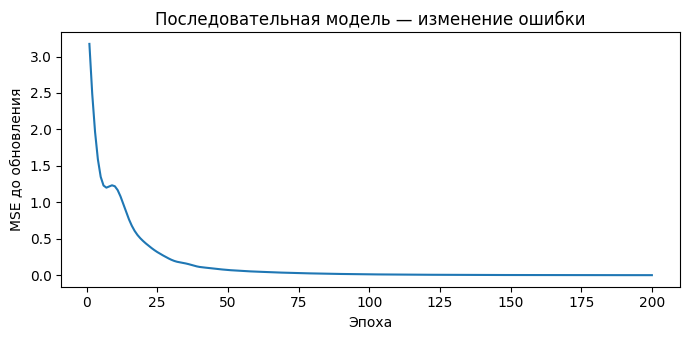

In [21]:
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 201), curve_losses)
plt.xlabel("Эпоха")
plt.ylabel("MSE до обновления")
plt.title("Последовательная модель — изменение ошибки")
plt.tight_layout()
plt.show()

Кривая показывает ошибку, по которой на каждой эпохе вычислялось очередное обновление.
Теперь посмотрим на сами предсказания.
Изгиб создаётся совместной работой нескольких участков `ReLU`, а не добавлением готового признака $x^2$ на вход.

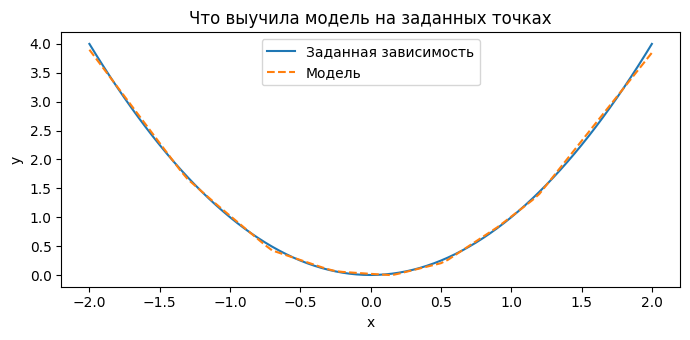

In [22]:
plt.figure(figsize=(7, 3.5))
plt.plot(x_curve.numpy(), y_curve.numpy(), label="Заданная зависимость")
plt.plot(x_curve.numpy(), curve_prediction.numpy(), "--", label="Модель")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Что выучила модель на заданных точках")
plt.legend()
plt.tight_layout()
plt.show()

### 3.8. Ошибка классификации

В классификации модель возвращает по одной оценке для каждого класса.
Эти оценки называются логитами.
Номер наибольшего логита становится ответом модели.

`softmax` переводит логиты в вероятностное представление.
Для правильного класса с номером $y_i$ потеря равна $-\log p_{i,y_i}$.
Средняя потеря пакета получается усреднением этих значений.

В `nn.CrossEntropyLoss` передаются **исходные логиты**, а не результат `softmax` [7].
Числовые метки классов здесь имеют тип `torch.long` и форму `(N,)`.

In [23]:
logits = torch.tensor([[2., 1., 0.], [0., 1., 2.]])
labels = torch.tensor([0, 2], dtype=torch.long)
probabilities = torch.softmax(logits, dim=1)
manual_loss = -torch.log(probabilities[torch.arange(2), labels]).mean()
loss = nn.CrossEntropyLoss()(logits, labels)

print("Вероятности\n", probabilities)
print("Ответы", logits.argmax(dim=1))
print("Вручную", manual_loss.item(), "CrossEntropyLoss", loss.item())

Вероятности
 tensor([[0.665, 0.245, 0.090],
        [0.090, 0.245, 0.665]])
Ответы tensor([0, 2])
Вручную 0.40760597586631775 CrossEntropyLoss 0.40760594606399536


## 4. Линейная классификация цифр MNIST

### 4.1. Сначала отделим набор данных от пакета

`Dataset` отвечает за доступ к **одному** объекту [8].
Метод `__len__` возвращает число объектов.
Метод `__getitem__` получает индекс и возвращает соответствующую пару «признаки — ответ».

Определим небольшой класс с этими двумя операциями.
`__init__` сохранит исходные массивы внутри экземпляра.
`self` обозначает тот экземпляр набора, к которому обращается программа.

In [24]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

class PairsDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]

features = torch.arange(12, dtype=torch.float32).reshape(6, 2)
targets = torch.tensor([0, 1, 0, 1, 0, 1])
pairs = PairsDataset(features, targets)
print("Всего объектов", len(pairs))
print("Объект с индексом 2", pairs[2])

Всего объектов 6
Объект с индексом 2 (tensor([4., 5.]), tensor(0))


### 4.2. Соберём пакет вручную и через `DataLoader`

`DataLoader` получает несколько объектов у `Dataset` и собирает их в пакет [8].
Для нашего набора он складывает векторы признаков в матрицу, а метки — в вектор.
Операция `torch.stack` показывает, как выглядит такое объединение тензоров.

`batch_size=2` задаёт два объекта в пакете.
`shuffle=False` сохраняет порядок индексов.
`num_workers=0` означает чтение в основном процессе, без дополнительных процессов загрузки.

In [25]:
manual_features = torch.stack([pairs[0][0], pairs[1][0]])
manual_targets = torch.stack([pairs[0][1], pairs[1][1]])
print("Ручной пакет\n", manual_features, manual_targets)

loader = DataLoader(pairs, batch_size=2, shuffle=False, num_workers=0)
for batch_number, (x_batch, y_batch) in enumerate(loader):
    print("Пакет", batch_number, "формы", x_batch.shape, y_batch.shape)
    print(x_batch, y_batch)

print("len(Dataset)", len(pairs), "len(DataLoader)", len(loader))

Ручной пакет
 tensor([[0., 1.],
        [2., 3.]]) tensor([0, 1])
Пакет 0 формы torch.Size([2, 2]) torch.Size([2])
tensor([[0., 1.],
        [2., 3.]]) tensor([0, 1])
Пакет 1 формы torch.Size([2, 2]) torch.Size([2])
tensor([[4., 5.],
        [6., 7.]]) tensor([0, 1])
Пакет 2 формы torch.Size([2, 2]) torch.Size([2])
tensor([[ 8.,  9.],
        [10., 11.]]) tensor([0, 1])
len(Dataset) 6 len(DataLoader) 3


При `shuffle=True` загрузчик меняет порядок индексов при новом проходе.
При этом признаки остаются связаны со своими метками.
Один проход по всем пакетам называется эпохой.
Последний пакет может содержать меньше объектов, если размер набора не делится на `batch_size`.

Когда данные уже представлены согласованными тензорами, вместо нашего класса можно использовать готовый `TensorDataset`.
В этой ситуации он решает ту же задачу.

In [26]:
tensor_pairs = TensorDataset(features, targets)
print("Тот же объект из TensorDataset", tensor_pairs[2])

shuffled_loader = DataLoader(
    pairs, batch_size=4, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
for x_batch, y_batch in shuffled_loader:
    print("Признаки", x_batch.tolist(), "метки", y_batch.tolist())

Тот же объект из TensorDataset (tensor([4., 5.]), tensor(0))
Признаки [[8.0, 9.0], [10.0, 11.0], [0.0, 1.0], [2.0, 3.0]] метки [0, 1, 0, 1]
Признаки [[4.0, 5.0], [6.0, 7.0]] метки [0, 1]


### 4.3. Прочитаем MNIST и рассмотрим один объект

`torchvision.datasets.MNIST` — готовая реализация `Dataset` для цифр [9].
Она загружает данные, возвращает изображение с меткой и применяет переданное преобразование.
Аргумент `train=True` выбирает исходную обучающую часть.
`download=True` разрешает скачать недостающие файлы.

Используем `transforms.ToTensor()` для перевода изображения в тензор.
Для исходных пикселей `uint8` это преобразование меняет диапазон `0…255` на `0…1` и помещает ось канала первой [10].
У изображения цифры один канал, поэтому форма результата равна `(1, 28, 28)`.

Все следующие ячейки этого раздела требуют наличия датсета MNIST.

In [27]:
import torchvision
from torchvision import datasets, transforms

mnist_source = datasets.MNIST(
    root="practice8_data", train=True, download=True,
    transform=transforms.ToTensor()
)
image, label = mnist_source[0]
manual_image = mnist_source.data[0].unsqueeze(0).float() / 255

print("Torchvision", torchvision.__version__)
print("Это Dataset", isinstance(mnist_source, Dataset))
print("Объектов", len(mnist_source))
print("Изображение", image.shape, image.dtype)
print("Диапазон", image.min().item(), image.max().item(), "Метка", label)

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 967kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.34MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.36MB/s]

Torchvision 0.26.0+cpu
Это Dataset True
Объектов 60000
Изображение torch.Size([1, 28, 28]) torch.float32
Диапазон 0.0 1.0 Метка 5


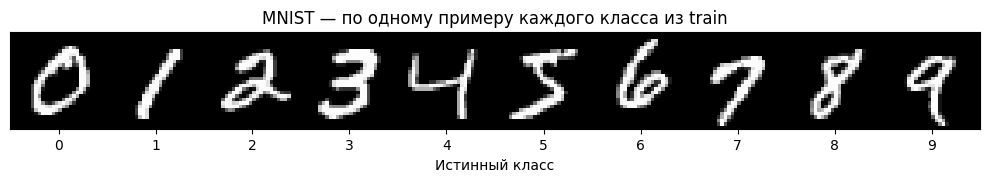

In [28]:
examples = []
for digit in range(10):
    index = torch.where(mnist_source.targets == digit)[0][0].item()
    examples.append(mnist_source[index][0])

strip = torch.cat(examples, dim=2).squeeze(0)
plt.figure(figsize=(10, 2.8))
# Для показа оттенков серого используем одинаковые значения R, G и B.
plt.imshow(np.repeat(strip.numpy()[:, :, None], 3, axis=2), interpolation="nearest")
plt.xticks(np.arange(10) * 28 + 13.5, range(10))
plt.yticks([])
plt.xlabel("Истинный класс")
plt.title("MNIST — по одному примеру каждого класса из train")
plt.tight_layout()
plt.show()

### 4.4. Выделим обучение и проверку

Для демонстрации возьмём 10 000 обучающих и 2 000 проверочных объектов.
Оставшиеся изображения исходной обучающей части в этом опыте не используются.
`random_split` возвращает непересекающиеся подмножества одного `Dataset`.
Генератор с фиксированным начальным состоянием позволяет повторить выбор индексов.

Проверочная часть `valid` нужна для наблюдения за качеством по эпохам.
Официальную тестовую часть откроем только после обучения.
Для `valid` перемешивание не требуется.

In [29]:
mnist_train, mnist_valid, mnist_unused = random_split(
    mnist_source, [10000, 2000, len(mnist_source) - 12000],
    generator=torch.Generator().manual_seed(42)
)
mnist_train_loader = DataLoader(
    mnist_train, batch_size=128, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
mnist_valid_loader = DataLoader(
    mnist_valid, batch_size=256, shuffle=False, num_workers=0
)
images, labels = next(iter(mnist_train_loader))
print("Train", len(mnist_train), "Valid", len(mnist_valid))
print("Пакет изображений", images.shape, images.dtype)
print("Пакет меток", labels.shape, labels.dtype)

Train 10000 Valid 2000
Пакет изображений torch.Size([128, 1, 28, 28]) torch.float32
Пакет меток torch.Size([128]) torch.int64


### 4.5. Соберём линейный классификатор

`Flatten` сохраняет первую ось пакета и объединяет остальные оси.
Каждое изображение становится вектором из $1\cdot28\cdot28=784$ чисел.
Линейный слой создаёт десять логитов.

Здесь нет скрытого слоя и `ReLU`.
Это линейный классификатор по пикселям, записанный через `nn.Sequential`.
Вместе с `CrossEntropyLoss` он обучается как многоклассовая логистическая регрессия.

Создадим модель заново перед основным циклом обучения.
Число параметров равно $(784+1)\cdot10=7850$.

In [30]:
torch.manual_seed(42)
mnist_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 10)
).to(device)

print(mnist_model)
print("Параметров", sum(p.numel() for p in mnist_model.parameters()))
with torch.no_grad():
    logits = mnist_model(images.to(device))
print("Форма логитов", logits.shape)
print("Первые ответы до обучения", logits.argmax(dim=1)[:10].cpu())

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)
Параметров 7850
Форма логитов torch.Size([128, 10])
Первые ответы до обучения tensor([3, 9, 8, 6, 6, 9, 3, 6, 3, 9])


### 4.6. Выполним обычный цикл обучения

Внешний цикл проходит по эпохам.
Внутренний цикл получает пакеты из `DataLoader`.
Для каждого пакета повторяются уже разобранные операции `zero_grad`, вычисление логитов и потерь, `backward`, `step`.

`model.train()` переключает слои в режим обучения.
`model.eval()` переключает их в режим применения.
Для текущих `Flatten` и `Linear` это не меняет формулу, но после введения `BatchNorm2d` различие станет существенным.
`torch.no_grad()` отдельно отключает построение графа производных во время проверки.

Потерю пакета умножаем на число его объектов, прежде чем добавить к сумме.
Так последний неполный пакет получает правильный вес.
Пять эпох заданы заранее, для итогового теста используются параметры после пятой эпохи.

In [31]:
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(mnist_model.parameters(), lr=0.001)
mnist_history = []

for epoch in range(5):  # У нас будет 5 полных проходов обучения по набору данных
    mnist_model.train() # Перевод модели в train режим обучения параметров
    loss_sum = 0.0      # тут будет расчет ошибок на эпохе
    for images, labels in mnist_train_loader: # Перебор данных из датасета

        # Вычисление на устройстве cpu/gpu в зависимости от конфигурации
        images = images.to(device)
        labels = labels.to(device)

        # Backward копит градиенты на тензорах, поэтому обнуляем их перед каждым шагом обновления
        optimizer.zero_grad()

        # Вычисляем шансы классов на изображениях, потери и считаем градиенты на параметрах
        logits = mnist_model(images)
        loss = loss_function(logits, labels)
        loss.backward()

        # Делаем шаг на параметрах с помощью полученных градиентов из .backward()
        optimizer.step()

        # расчет суммы потерь на эпохе
        loss_sum += loss.item() * len(labels)

    # режим валидации без расчета градиентов и обучения параметров
    mnist_model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in mnist_valid_loader:
            logits = mnist_model(images.to(device))
            correct += (logits.argmax(dim=1).cpu() == labels).sum().item()

    train_loss = loss_sum / len(mnist_train)
    valid_accuracy = correct / len(mnist_valid)
    mnist_history.append([epoch + 1, train_loss, valid_accuracy])
    print(f"Эпоха {epoch + 1}: loss={train_loss:.4f}, valid={valid_accuracy:.3f}")

Эпоха 1: loss=1.3621, valid=0.840
Эпоха 2: loss=0.7072, valid=0.868
Эпоха 3: loss=0.5474, valid=0.882
Эпоха 4: loss=0.4701, valid=0.891
Эпоха 5: loss=0.4250, valid=0.891


Потеря и доля верных ответов отвечают на разные вопросы.
Первая учитывает величину логитов через вероятностную модель.
Вторая учитывает только совпадение выбранного класса с меткой.
На графике найдите участок наиболее заметного изменения доли верных ответов.

,epoch,train_loss,valid_accuracy
0,1,1.3621,0.8400
1,2,0.7072,0.8680
2,3,0.5474,0.8825
3,4,0.4701,0.8915
4,5,0.4250,0.8910


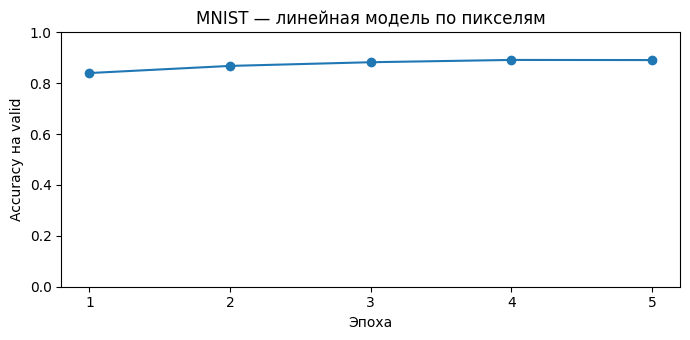

In [32]:
mnist_history = pd.DataFrame(
    mnist_history, columns=["epoch", "train_loss", "valid_accuracy"]
)
display(mnist_history.round(4))
plt.figure(figsize=(7, 3.5))
plt.plot(mnist_history.epoch, mnist_history.valid_accuracy, marker="o")
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.xlabel("Эпоха")
plt.ylabel("Accuracy на valid")
plt.title("MNIST — линейная модель по пикселям")
plt.tight_layout()
plt.show()

### 4.7. Проверим модель на тестовых цифрах

Теперь загрузим официальную тестовую часть.
Параметры модели больше не меняются.
`argmax(dim=1)` выбирает индекс наибольшего логита отдельно для каждой строки пакета.
Для такого выбора вычислять `softmax` не требуется.

Матрица ошибок показывает, какие классы модель смешивает.
Её строки соответствуют истинным цифрам, столбцы — предсказанным.

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score

mnist_test = datasets.MNIST(
    root="practice8_data", train=False, download=True,
    transform=transforms.ToTensor()
)
mnist_test_loader = DataLoader(
    mnist_test, batch_size=256, shuffle=False, num_workers=0
)

mnist_model.eval()
mnist_predictions = []
mnist_answers = []
with torch.no_grad():
    for images, labels in mnist_test_loader:
        logits = mnist_model(images.to(device))
        mnist_predictions.append(logits.argmax(dim=1).cpu())
        mnist_answers.append(labels)
mnist_predictions = torch.cat(mnist_predictions).numpy()
mnist_answers = torch.cat(mnist_answers).numpy()
print("Объектов test", len(mnist_test))
print("Accuracy test", accuracy_score(mnist_answers, mnist_predictions))

Объектов test 10000
Accuracy test 0.8977


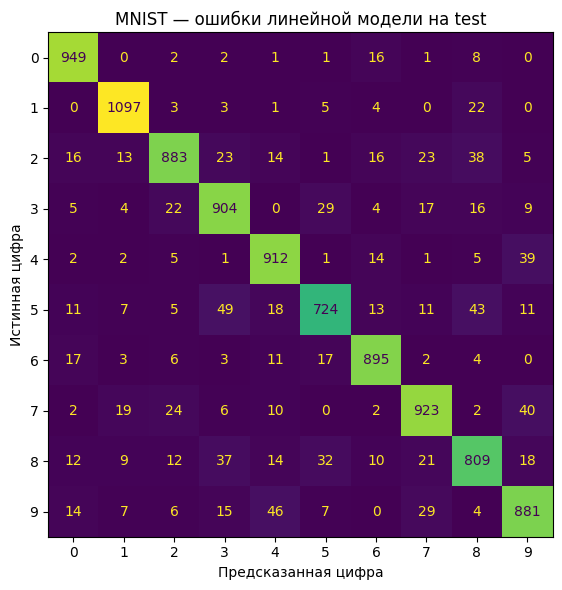

In [34]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    mnist_answers, mnist_predictions, labels=range(10),
    ax=ax, colorbar=False
)
ax.set_xlabel("Предсказанная цифра")
ax.set_ylabel("Истинная цифра")
ax.set_title("MNIST — ошибки линейной модели на test")
plt.tight_layout()
plt.show()

### 4.8. Посмотрим на одну строку весов

У каждого выходного класса есть 784 веса.
Вернём строке весов для цифры 3 форму изображения.
Положительный вес увеличивает логит этого класса при увеличении яркости соответствующего пикселя.
Отрицательный вес уменьшает его.
Итоговый ответ зависит также от остальных девяти логитов.

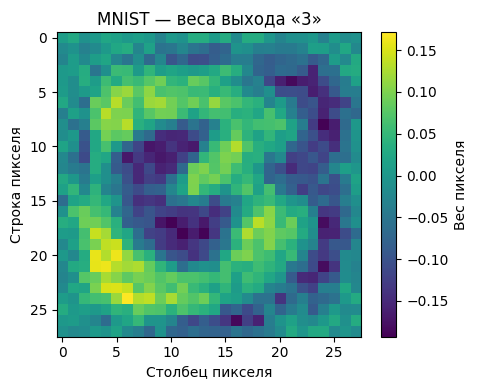

In [35]:
weight_image = mnist_model[1].weight[3].detach().cpu().reshape(28, 28)
plt.figure(figsize=(5, 4))
plt.imshow(weight_image, interpolation="nearest")
plt.colorbar(label="Вес пикселя")
plt.xlabel("Столбец пикселя")
plt.ylabel("Строка пикселя")
plt.title("MNIST — веса выхода «3»")
plt.tight_layout()
plt.show()

## 5. Слои для двумерных карт

В предыдущей модели каждый выход связан со всеми пикселями.
Теперь начнём с небольших пространственных областей.
Все числовые примеры этой части выполняются без скачивания изображений.

### 5.1. Максимальный и средний пулинг

В PyTorch выбирают конкретный вид пулинга, например `nn.MaxPool2d` или `nn.AvgPool2d` [11, 12].
Отдельного универсального слоя `nn.Pooling2d` здесь нет.

Разобьём карту $4\times4$ на четыре области $2\times2$.
Максимальный пулинг оставит наибольшее число каждой области.
Средний пулинг заменит её средним.
При `kernel_size=2` и `stride=2` обе операции дадут карту $2\times2$.
Обучаемых весов у этих операций нет.

In [36]:
map_2d = torch.tensor([[1., 2., 3., 4.],
                       [5., 6., 7., 8.],
                       [9., 10., 11., 12.],
                       [13., 14., 15., 16.]])
map_4d = map_2d.unsqueeze(0).unsqueeze(0)
max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)

print("Вход NCHW", map_4d.shape)
print("Первый блок\n", map_2d[:2, :2])
print("Его максимум", map_2d[:2, :2].max().item())
print("Его среднее", map_2d[:2, :2].mean().item())
print("MaxPool\n", max_pool(map_4d)[0, 0])
print("AvgPool\n", avg_pool(map_4d)[0, 0])

Вход NCHW torch.Size([1, 1, 4, 4])
Первый блок
 tensor([[1., 2.],
        [5., 6.]])
Его максимум 6.0
Его среднее 3.5
MaxPool
 tensor([[ 6.,  8.],
        [14., 16.]])
AvgPool
 tensor([[ 3.500,  5.500],
        [11.500, 13.500]])


### 5.2. Один фильтр свёртки

Положим матрицу весов $3\times3$ на участок входной карты.
Перемножим соответствующие числа и сложим девять произведений.
Это значение одной позиции выходной карты.
После сдвига окна используется та же матрица весов.

$$Y_{i,j}=\sum_{u=0}^{2}\sum_{v=0}^{2}X_{i+u,j+v}K_{u,v}.$$

В `nn.Conv2d` ядро применяется без переворота, то есть вычисляется взаимная корреляция [13].
В терминологии нейронных сетей эту операцию называют свёрткой.
Для опыта зададим фильтр сами, а в CNN его веса будут обучаться.

In [37]:
map_2d = torch.tensor([[0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.]])
kernel = torch.tensor([[-1., 0., 1.],
                       [-1., 0., 1.],
                       [-1., 0., 1.]])
patch = map_2d[:3, :3]
print("Первое окно\n", patch)
print("Произведения\n", patch * kernel)
print("Первый отклик", (patch * kernel).sum().item())

manual_map = torch.zeros(3, 3)
for row in range(3):
    for column in range(3):
        patch = map_2d[row:row + 3, column:column + 3]
        manual_map[row, column] = (patch * kernel).sum()
print("Вся карта вручную\n", manual_map)

Первое окно
 tensor([[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.]])
Произведения
 tensor([[-0., 0., 1.],
        [-0., 0., 1.],
        [-0., 0., 1.]])
Первый отклик 3.0
Вся карта вручную
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


### 5.3. Тот же расчёт через `nn.Conv2d`

Аргумент `in_channels=1` соответствует одной входной карте.
`out_channels=1` задаёт одну выходную карту.
Размер ядра равен трём.
Смещение отключено через `bias=False`, чтобы повторить предыдущую формулу.

Веса имеют форму `(выходные каналы, входные каналы, высота ядра, ширина ядра)`.
Здесь это `(1, 1, 3, 3)`.
Объём пакета не входит в форму весов.

In [38]:
conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[0, 0].copy_(kernel)
    output = conv(map_2d[None, None])

print("Форма весов", conv.weight.shape)
print("Форма выхода", output.shape)
print("Результат Conv2d\n", output[0, 0])
assert torch.allclose(output[0, 0], manual_map)

Форма весов torch.Size([1, 1, 3, 3])
Форма выхода torch.Size([1, 1, 3, 3])
Результат Conv2d
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


На рисунке покажем числовые отклики.
Входной скачок яркости расположен между вторым и третьим столбцами.
Выходные позиции относятся к положениям окна, поэтому координаты карты короче координат входа.

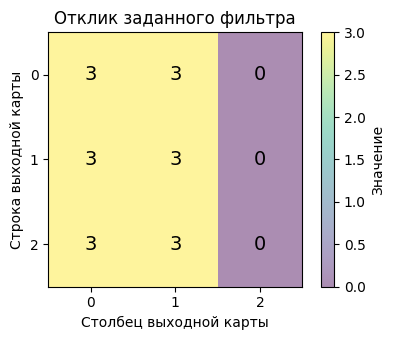

In [39]:
plt.figure(figsize=(4.5, 3.5))
plt.imshow(output[0, 0], interpolation="nearest", alpha=0.45)
for row in range(3):
    for column in range(3):
        plt.text(column, row, f"{output[0, 0, row, column]:.0f}",
                 ha="center", va="center", fontsize=14)
plt.xticks(range(3))
plt.yticks(range(3))
plt.xlabel("Столбец выходной карты")
plt.ylabel("Строка выходной карты")
plt.title("Отклик заданного фильтра")
plt.colorbar(label="Значение")
plt.tight_layout()
plt.show()

### 5.4. Шаг и дополнение границ

`stride` задаёт шаг перемещения окна.
`padding` добавляет значения по границам, по умолчанию нули.
При ядре $K$, шаге $S$ и дополнении $P$ высота выхода для наших слоёв равна

$$H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1.$$

Для ширины применяется такая же формула.
Проверим три варианта на прежней карте $5\times5$.
Число весов фильтра остаётся равным девяти.

In [40]:
rows = []
for padding, stride in [(0, 1), (1, 1), (1, 2)]:
    conv = nn.Conv2d(1, 1, 3, padding=padding, stride=stride, bias=False)
    with torch.no_grad():
        conv.weight[0, 0].copy_(kernel)
        result = conv(map_2d[None, None])
    rows.append([padding, stride, tuple(result.shape),
                 sum(p.numel() for p in conv.parameters())])
pd.DataFrame(rows, columns=["padding", "stride", "Форма выхода", "Параметров"])

,padding,stride,Форма выхода,Параметров
0,0,1,"(1, 1, 3, 3)",9
1,1,1,"(1, 1, 5, 5)",9
2,1,2,"(1, 1, 3, 3)",9


### 5.5. Что происходит с несколькими каналами

Одна выходная карта суммирует отклики по всем входным каналам.
Для каждого входного канала у неё есть свой срез ядра.
Вторая выходная карта использует другой комплект весов [13].

Поэтому число весов обычного `Conv2d` равно $C_{out}C_{in}K_HK_W$.
При включённом смещении добавляются ещё $C_{out}$ чисел.
Создадим два входных канала и две выходные карты.
У первой карты все веса будут равны единице, у второй — минус единице.

In [41]:
two_channels = torch.stack([map_2d, 2 * map_2d]).unsqueeze(0)
conv = nn.Conv2d(2, 2, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[0].fill_(1)
    conv.weight[1].fill_(-1)
    result = conv(two_channels)

manual_first = two_channels[0, :, :3, :3].sum()
print("Вход", two_channels.shape, "Веса", conv.weight.shape)
print("Выход", result.shape)
print("Первая позиция вручную", manual_first.item())
print("Первая выходная карта\n", result[0, 0])
print("Вторая выходная карта\n", result[0, 1])

Вход torch.Size([1, 2, 5, 5]) Веса torch.Size([2, 2, 3, 3])
Выход torch.Size([1, 2, 3, 3])
Первая позиция вручную 9.0
Первая выходная карта
 tensor([[ 9., 18., 27.],
        [ 9., 18., 27.],
        [ 9., 18., 27.]])
Вторая выходная карта
 tensor([[ -9., -18., -27.],
        [ -9., -18., -27.],
        [ -9., -18., -27.]])


### 5.6. `BatchNorm2d` — нормирование каждого канала

Свёртка создала карты признаков.
`BatchNorm2d(C)` обрабатывает каждый из $C$ каналов отдельно [14].
В режиме обучения среднее и дисперсия вычисляются по всем объектам пакета и пространственным позициям данного канала.
Для тензора NCHW это оси `0`, `2`, `3`.

$$\hat x_{n,c,h,w}=\frac{x_{n,c,h,w}-\mu_c}{\sqrt{\sigma_c^2+\varepsilon}},
\qquad y_{n,c,h,w}=\gamma_c\hat x_{n,c,h,w}+\beta_c.$$

$\varepsilon$ защищает знаменатель от нуля.
$\gamma_c$ и $\beta_c$ являются обучаемыми масштабом и смещением.
Изначально они равны единице и нулю.
Число обучаемых параметров равно $2C$, а форма карты сохраняется.

In [42]:
maps = torch.arange(1, 17, dtype=torch.float32).reshape(2, 2, 2, 2)
bn = nn.BatchNorm2d(2, eps=1e-5, momentum=0.1)
bn.train()

mean = maps.mean(dim=(0, 2, 3), keepdim=True)
variance = maps.var(dim=(0, 2, 3), unbiased=False, keepdim=True)
manual_normalized = (maps - mean) / torch.sqrt(variance + 1e-5)
with torch.no_grad():
    normalized = bn(maps)

print("Среднее каждого канала до", mean.flatten())
print("Дисперсия каждого канала до", variance.flatten())
print("Средние после", normalized.mean(dim=(0, 2, 3)))
print("Дисперсии после", normalized.var(dim=(0, 2, 3), unbiased=False))
print("Форма", normalized.shape, "Параметров", sum(p.numel() for p in bn.parameters()))

Среднее каждого канала до tensor([ 6.500, 10.500])
Дисперсия каждого канала до tensor([17.250, 17.250])
Средние после tensor([0.000, 0.000])
Дисперсии после tensor([1.000, 1.000])
Форма torch.Size([2, 2, 2, 2]) Параметров 4


### 5.7. Почему при проверке нужен `eval()`

При обучении `BatchNorm2d` также обновляет накопленные средние и дисперсии.
При `momentum=0.1` новая статистика входит в накопленную оценку с весом 0.1.
В режиме `eval()` слой использует эти оценки вместо статистик текущего пакета [14].

В обучающем прямом проходе дисперсия считается с делением на число значений, что в коде задано `unbiased=False`.
Для обновления накопленной дисперсии PyTorch использует оценку с делением на число значений минус один.

После одного пакета накопленные статистики ещё заметно отличаются от его статистик.
Поэтому результат `eval()` не обязан иметь нулевое среднее.

In [43]:
print("Накопленное среднее", bn.running_mean)
print("Накопленная дисперсия", bn.running_var)
bn.eval()
with torch.no_grad():
    evaluated = bn(maps)
    manual_eval = (maps - bn.running_mean[None, :, None, None])
    manual_eval = manual_eval / torch.sqrt(bn.running_var[None, :, None, None] + bn.eps)
    manual_eval = manual_eval * bn.weight[None, :, None, None] + bn.bias[None, :, None, None]
print("Средние выхода eval", evaluated.mean(dim=(0, 2, 3)))
print("Число обработанных обучающих пакетов", bn.num_batches_tracked.item())

Накопленное среднее tensor([0.650, 1.050])
Накопленная дисперсия tensor([2.871, 2.871])
Средние выхода eval tensor([3.452, 5.577])
Число обработанных обучающих пакетов 1


`train()` и `eval()` выбирают поведение слоёв, но не запускают обучение сами по себе.
Изменение обучаемых параметров по-прежнему выполняет оптимизатор.
Накопленные статистики BatchNorm обновляются при обучающем прямом проходе, даже внутри `no_grad()`.
Это отдельные буферы, а не параметры, изменяемые `optimizer.step()`.

| Операция | Как меняется форма | Что хранится и обучается |
|---|---|---|
| `Conv2d` | Могут измениться каналы, высота и ширина | Ядра и, при включении, смещения |
| `MaxPool2d`, `AvgPool2d` | Уменьшаются высота и ширина | Обучаемых параметров нет |
| `BatchNorm2d` | Форма сохраняется | Масштаб и смещение канала, отдельно накопленные статистики |
| `ReLU` | Форма сохраняется | Обучаемых параметров нет |
| `Flatten` | Пространственные оси объединяются в вектор | Обучаемых параметров нет |

Теперь каждый слой будущей CNN уже был применён отдельно.

## 6. Сравнение моделей на BloodMNIST

### 6.1. Прочитаем цветные изображения клеток

BloodMNIST входит в коллекцию MedMNIST.
Здесь используем версию 28 × 28 RGB с восемью классами и официальными частями `train`, `val`, `test` [15].
Читаем сам файл NPZ, чтобы видеть исходные массивы до создания `Dataset`.
Отдельный пакет `medmnist` для этого способа загрузки не требуется.

`download_url` проверит контрольную сумму существующего файла или загрузит его с официального адреса.
При работе без интернета заранее поместите `bloodmnist.npz` в указанный каталог.
Внутри архива изображения имеют порядок осей NHWC, а метки хранятся отдельно.

In [44]:
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.datasets.utils import download_url

blood_root = Path("practice8_data")
blood_root.mkdir(exist_ok=True)
download_url(
    "https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1",
    root=str(blood_root), filename="bloodmnist.npz",
    md5="7053d0359d879ad8a5505303e11de1dc"
)
with np.load(blood_root / "bloodmnist.npz") as data:
    blood_train_images = data["train_images"]
    blood_train_labels = data["train_labels"].reshape(-1)
    blood_valid_images = data["val_images"]
    blood_valid_labels = data["val_labels"].reshape(-1)
    blood_test_images = data["test_images"]
    blood_test_labels = data["test_labels"].reshape(-1)

print("Train", blood_train_images.shape, blood_train_labels.shape)
print("Valid", blood_valid_images.shape, blood_valid_labels.shape)
print("Test", blood_test_images.shape, blood_test_labels.shape)

100%|██████████| 35.5M/35.5M [00:10<00:00, 3.37MB/s]


Train (11959, 28, 28, 3) (11959,)
Valid (1712, 28, 28, 3) (1712,)
Test (3421, 28, 28, 3) (3421,)


Названия ниже соответствуют числовым меткам исходного набора [15].
Сначала посмотрим на обучающие изображения.
Метки на рисунке оставим числовыми, а полные названия вынесем в таблицу.
Так небольшие изображения не будут перекрыты длинными подписями.

,Код,Класс,Изображений в исходном train
0,0,Базофил,852
1,1,Эозинофил,2181
2,2,Эритробласт,1085
3,3,Незрелые гранулоциты,2026
4,4,Лимфоцит,849
5,5,Моноцит,993
6,6,Нейтрофил,2330
7,7,Тромбоцит,1643


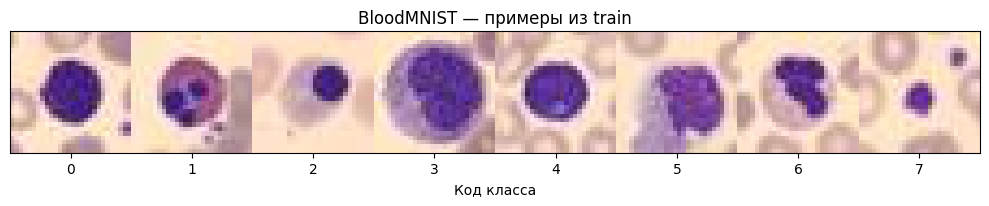

In [45]:
blood_names = ["Базофил", "Эозинофил", "Эритробласт",
               "Незрелые гранулоциты", "Лимфоцит", "Моноцит",
               "Нейтрофил", "Тромбоцит"]
display(pd.DataFrame({"Код": range(8), "Класс": blood_names,
    "Изображений в исходном train": np.bincount(blood_train_labels, minlength=8)}))
example_indices = [np.flatnonzero(blood_train_labels == k)[0] for k in range(8)]
strip = np.concatenate(blood_train_images[example_indices], axis=1)
plt.figure(figsize=(10, 3))
plt.imshow(strip)
plt.xticks(np.arange(8) * 28 + 13.5, range(8))
plt.yticks([])
plt.xlabel("Код класса")
plt.title("BloodMNIST — примеры из train")
plt.tight_layout()
plt.show()

### 6.2. Что изменяет предварительная обработка

Перед обучением рассмотрим несколько преобразований одного изображения.
Перевод в оттенки серого убирает цветовые различия.
Сглаживание ослабляет мелкие изменения яркости.
Уменьшение изображения сокращает число пикселей, а обратное увеличение не восстанавливает исходные детали.

Выбор преобразований зависит от задачи.
В основной модели сохраним цвет и исходный размер.

| Действие | Когда его применяют | Что проверить в задаче |
|---|---|---|
| Изменение размера | Нужен единый размер входа или меньший объём вычислений | Сохранились ли мелкие объекты и детали |
| Оттенки серого | Важна форма, а цвет не используется | Не различаются ли классы именно цветом |
| Сглаживание | Нужно ослабить мелкий шум | Не исчезли ли полезные границы и текстура |
| Нормирование | Нужен заданный числовой масштаб входа | Одинаково ли правило при обучении и применении |
| Отражение или поворот | Допустимы такие положения объекта | Сохраняется ли метка, например при повороте цифры |

Преобразование допустимо не потому, что оно доступно в библиотеке, а потому, что оно соответствует поставленной задаче.

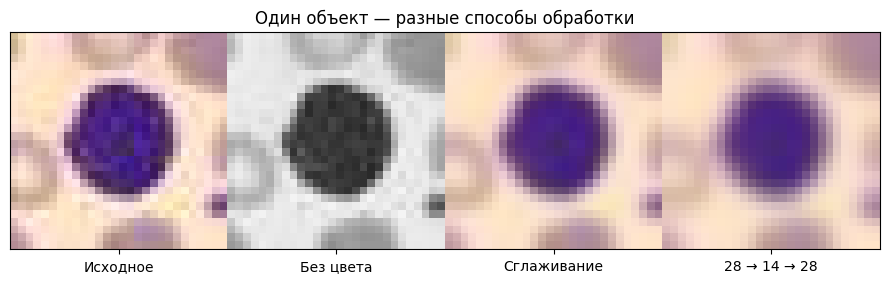

In [46]:
original = Image.fromarray(blood_train_images[example_indices[0]])
gray = transforms.Grayscale(num_output_channels=3)(original)
blurred = transforms.GaussianBlur(kernel_size=3, sigma=1.0)(original)
small = transforms.Resize((14, 14), antialias=True)(original)
resized_back = transforms.Resize((28, 28), antialias=True)(small)
strip = np.concatenate([np.array(im) for im in
                        [original, gray, blurred, resized_back]], axis=1)
plt.figure(figsize=(9, 3))
plt.imshow(strip)
plt.xticks(np.arange(4) * 28 + 13.5,
           ["Исходное", "Без цвета", "Сглаживание", "28 → 14 → 28"])
plt.yticks([])
plt.title("Один объект — разные способы обработки")
plt.tight_layout()
plt.show()

### 6.3. Опишем собственный `Dataset` для изображений

Здесь повторяется конструкция из раздела 4.1.
Вместо готового вектора `__getitem__` получает изображение из массива.
`Image.fromarray` создаёт объект изображения PIL.
После этого вызывается переданное преобразование `transform`.

`Compose` последовательно применяет преобразования к одному изображению.
Это подготовка данных, а не обучаемая модель `nn.Sequential`.

После `ToTensor()` применим `Normalize` с явно заданными средними 0.5 и масштабами 0.5.
Формула `(x - 0.5) / 0.5` переводит диапазон `0…1` в `−1…1`.
Это фиксированное масштабирование, а не оценка среднего и дисперсии по данным.
Для всех трёх частей используем одно правило.

In [47]:
class BloodDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index])
        image = self.transform(image)
        label = int(self.labels[index])
        return image, label

blood_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

### 6.4. Подготовим одинаковые данные для двух моделей

Для обучения отберём по 600 изображений каждого класса внутри официального `train`.
Получится 4 800 объектов.
Проверочную и тестовую части оставим целиком.
Это уменьшенный учебный опыт, а не обучение на полном BloodMNIST.

Сначала создаются три объекта `Dataset`.
Затем `DataLoader` задаёт способ объединения их объектов в пакеты.
Набор не знает о размере пакета, а загрузчик не знает об архитектуре модели.

In [48]:
rng = np.random.default_rng(42)
train_indices = []
for label in range(8):
    candidates = np.flatnonzero(blood_train_labels == label)
    train_indices.extend(rng.choice(candidates, size=600, replace=False))
train_indices = np.array(train_indices)

blood_train = BloodDataset(blood_train_images[train_indices],
                          blood_train_labels[train_indices], blood_transform)
blood_valid = BloodDataset(blood_valid_images, blood_valid_labels, blood_transform)
blood_test = BloodDataset(blood_test_images, blood_test_labels, blood_transform)
blood_valid_loader = DataLoader(blood_valid, batch_size=256, shuffle=False, num_workers=0)
blood_test_loader = DataLoader(blood_test, batch_size=256, shuffle=False, num_workers=0)

image, label = blood_train[0]
print("Объект", image.shape, image.dtype, "Метка", label)
print("Train", len(blood_train), "Valid", len(blood_valid), "Test", len(blood_test))

Объект torch.Size([3, 28, 28]) torch.float32 Метка 0
Train 4800 Valid 1712 Test 3421


### 6.5. Две модели из уже знакомых слоёв

Первая модель разворачивает RGB-изображение в 2352 числа и получает восемь логитов одним линейным слоем.
Вторая сначала строит карты признаков и уменьшает их размер.
После двух пулингов высота и ширина изменяются $28\to14\to7$.
Классификатор CNN получает вектор длины $16\cdot7\cdot7=784$.

В свёртках перед BatchNorm отключено смещение.
Обучаемое смещение уже имеется в следующем нормирующем слое.
У каждой модели создаются новые параметры.
Веса MNIST сюда не переносятся.

In [49]:
torch.manual_seed(42)
blood_linear = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 28 * 28, 8)
).to(device)

torch.manual_seed(42)
blood_cnn = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(8),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 8)
).to(device)

print("Линейная модель", sum(p.numel() for p in blood_linear.parameters()))
print("CNN", sum(p.numel() for p in blood_cnn.parameters()))

Линейная модель 18824
CNN 7696


Посмотрим не только на итоговое число параметров, но и на форму данных после каждого слоя.
Для просмотра включим `eval()`, чтобы не менять накопленные статистики BatchNorm.
В таблице считаются обучаемые параметры.
Буферы `running_mean`, `running_var` и счётчик пакетов в это число не входят.

,Номер,Слой,Форма выхода,Параметров
0,0,Conv2d,"(1, 8, 28, 28)",216
1,1,BatchNorm2d,"(1, 8, 28, 28)",16
2,2,ReLU,"(1, 8, 28, 28)",0
3,3,MaxPool2d,"(1, 8, 14, 14)",0
4,4,Conv2d,"(1, 16, 14, 14)",1152
5,5,BatchNorm2d,"(1, 16, 14, 14)",32
6,6,ReLU,"(1, 16, 14, 14)",0
7,7,MaxPool2d,"(1, 16, 7, 7)",0
8,8,Flatten,"(1, 784)",0
9,9,Linear,"(1, 8)",6280


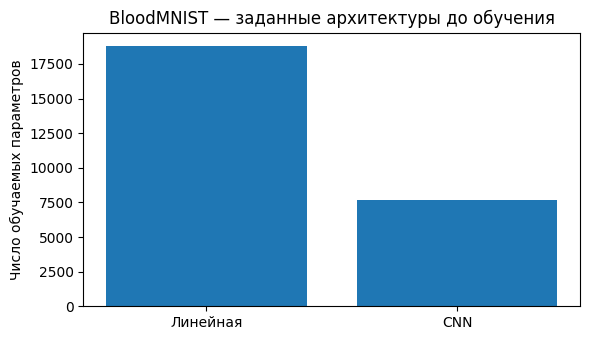

In [50]:
blood_cnn.eval()
current = torch.zeros(1, 3, 28, 28, device=device)
rows = []
with torch.no_grad():
    for index, layer in enumerate(blood_cnn):
        current = layer(current)
        rows.append([index, type(layer).__name__, tuple(current.shape),
                     sum(p.numel() for p in layer.parameters())])
display(pd.DataFrame(rows, columns=["Номер", "Слой", "Форма выхода", "Параметров"]))

parameter_counts = [sum(p.numel() for p in blood_linear.parameters()),
                    sum(p.numel() for p in blood_cnn.parameters())]
plt.figure(figsize=(6, 3.5))
plt.bar(["Линейная", "CNN"], parameter_counts)
plt.ylabel("Число обучаемых параметров")
plt.title("BloodMNIST — заданные архитектуры до обучения")
plt.tight_layout()
plt.show()

У линейной модели 18 824 параметра, у этой CNN — 7 696.
Свёртка повторно использует одно ядро в разных положениях, поэтому ей не нужны отдельные веса для каждой позиции изображения.
Однако она создаёт целые карты признаков.
Меньшее число параметров само по себе не означает меньше операций или меньшее время.

### 6.6. Обучим линейную модель

Повторим цикл MNIST без функции-обёртки.
Для обеих моделей зададим пять эпох, пакет из 128 изображений и Adam с шагом 0.001.
Перед обучением каждой модели создадим новый загрузчик с одинаковым начальным состоянием генератора.
Так последовательности обучающих пакетов будут совпадать.

Время измеряется от начала чтения обучающих пакетов до завершения обновлений эпохи.
Проверка `valid` не входит в этот интервал.
Синхронизация перед и после интервала дожидается завершения операций ускорителя [16].
На CPU эти условные ветви не выполняются.

In [51]:
from time import perf_counter

blood_train_loader = DataLoader(
    blood_train, batch_size=128, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
optimizer = optim.Adam(blood_linear.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()
linear_history = []

for epoch in range(5):
    blood_linear.train()
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    started = perf_counter()
    loss_sum = 0.0
    for images, labels in blood_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = blood_linear(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    train_seconds = perf_counter() - started

    blood_linear.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in blood_valid_loader:
            logits = blood_linear(images.to(device))
            correct += (logits.argmax(1).cpu() == labels).sum().item()
    valid_accuracy = correct / len(blood_valid)
    linear_history.append([epoch + 1, loss_sum / len(blood_train), valid_accuracy, train_seconds])
    print(f"Linear, эпоха {epoch + 1}: valid={valid_accuracy:.3f}, обучение={train_seconds:.2f} с")

Linear, эпоха 1: valid=0.689, обучение=2.14 с
Linear, эпоха 2: valid=0.723, обучение=1.09 с
Linear, эпоха 3: valid=0.721, обучение=1.09 с
Linear, эпоха 4: valid=0.742, обучение=1.06 с
Linear, эпоха 5: valid=0.756, обучение=1.09 с


### 6.7. Обучим CNN тем же способом

Внутри цикла меняется только объект модели.
`backward()` автоматически находит градиенты и для свёрточных ядер, и для параметров BatchNorm, и для последнего `Linear`.
В режиме `train()` BatchNorm использует статистики текущего пакета и обновляет накопленные оценки.
В режиме `eval()` применяются накопленные оценки.

Одинаковый шаг оптимизатора и число эпох задают общий демонстрационный бюджет.
Это сравнение двух конкретных настроек без отдельного подбора оптимальных параметров каждой архитектуры.

In [52]:
blood_train_loader = DataLoader(
    blood_train, batch_size=128, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
optimizer = optim.Adam(blood_cnn.parameters(), lr=0.001)
loss_function = nn.CrossEntropyLoss()
cnn_history = []

for epoch in range(5):
    blood_cnn.train()
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    started = perf_counter()
    loss_sum = 0.0
    for images, labels in blood_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = blood_cnn(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
    train_seconds = perf_counter() - started

    blood_cnn.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in blood_valid_loader:
            logits = blood_cnn(images.to(device))
            correct += (logits.argmax(1).cpu() == labels).sum().item()
    valid_accuracy = correct / len(blood_valid)
    cnn_history.append([epoch + 1, loss_sum / len(blood_train), valid_accuracy, train_seconds])
    print(f"CNN, эпоха {epoch + 1}: valid={valid_accuracy:.3f}, обучение={train_seconds:.2f} с")

CNN, эпоха 1: valid=0.458, обучение=2.29 с
CNN, эпоха 2: valid=0.770, обучение=5.08 с
CNN, эпоха 3: valid=0.827, обучение=2.20 с
CNN, эпоха 4: valid=0.847, обучение=2.14 с
CNN, эпоха 5: valid=0.855, обучение=2.19 с


### 6.8. Сравним ход обучения

На первом графике показана средняя потеря обучающих пакетов.
На втором — доля правильных ответов на `valid` после завершения каждой эпохи.
Параметры для итогового теста берём после пятой эпохи у обеих моделей.

Оцените, уменьшается ли потеря вместе с ростом проверочного качества.
По одному только уменьшению обучающей потери нельзя определить результат на новых изображениях.

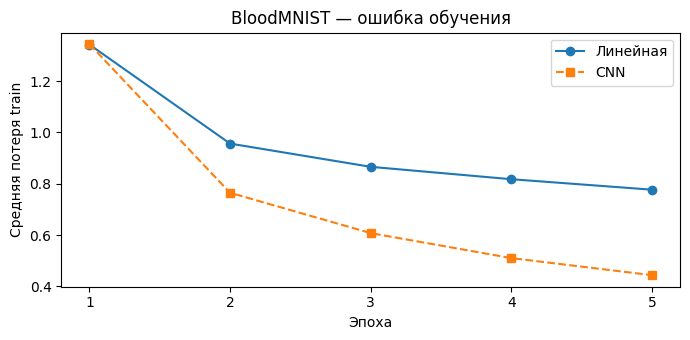

In [53]:
columns = ["epoch", "train_loss", "valid_accuracy", "train_seconds"]
linear_history = pd.DataFrame(linear_history, columns=columns)
cnn_history = pd.DataFrame(cnn_history, columns=columns)

plt.figure(figsize=(7, 3.5))
plt.plot(linear_history.epoch, linear_history.train_loss, "o-", label="Линейная")
plt.plot(cnn_history.epoch, cnn_history.train_loss, "s--", label="CNN")
plt.xticks(range(1, 6))
plt.xlabel("Эпоха")
plt.ylabel("Средняя потеря train")
plt.title("BloodMNIST — ошибка обучения")
plt.legend()
plt.tight_layout()
plt.show()

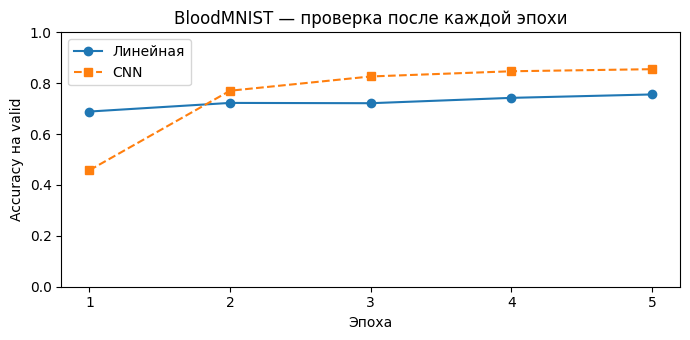

In [54]:
plt.figure(figsize=(7, 3.5))
plt.plot(linear_history.epoch, linear_history.valid_accuracy, "o-", label="Линейная")
plt.plot(cnn_history.epoch, cnn_history.valid_accuracy, "s--", label="CNN")
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.xlabel("Эпоха")
plt.ylabel("Accuracy на valid")
plt.title("BloodMNIST — проверка после каждой эпохи")
plt.legend()
plt.tight_layout()
plt.show()

### 6.9. Где находится вектор признаков CNN

Выведем карты после первого блока `Conv2d → BatchNorm2d → ReLU`.
Срез `blood_cnn[:3]` использует первые три уже обученных слоя.
Затем срез `blood_cnn[:-1]` выполнит все операции до последнего классификатора.
На выходе будет вектор из 784 чисел.

Последний слой действует над ним точно так же, как `Linear` во второй части работы.
Срез последовательности не обучается заново и использует те же параметры.

Карты первого блока torch.Size([1, 8, 28, 28])
Вектор признаков torch.Size([1, 784])
Логиты torch.Size([1, 8])


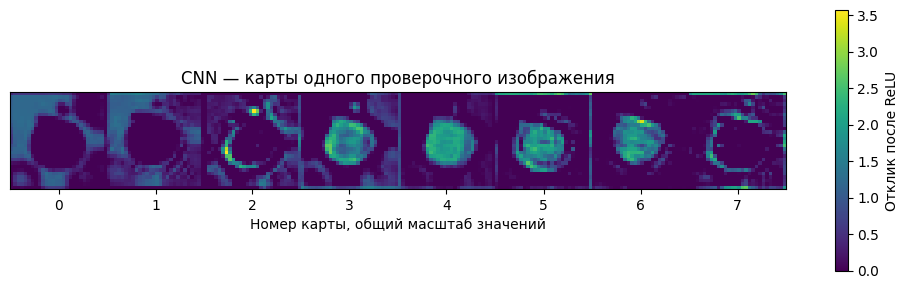

In [55]:
blood_cnn.eval()
image, label = blood_valid[0]
with torch.no_grad():
    x = image.unsqueeze(0).to(device)
    first_maps = blood_cnn[:3](x).cpu()
    feature_vector = blood_cnn[:-1](x)
    logits_from_vector = blood_cnn[-1](feature_vector)
    logits_direct = blood_cnn(x)

print("Карты первого блока", first_maps.shape)
print("Вектор признаков", feature_vector.shape)
print("Логиты", logits_from_vector.shape)

strip = torch.cat(list(first_maps[0]), dim=1)
plt.figure(figsize=(10, 3))
plt.imshow(strip, interpolation="nearest")
plt.xticks(np.arange(8) * 28 + 13.5, range(8))
plt.yticks([])
plt.xlabel("Номер карты, общий масштаб значений")
plt.title("CNN — карты одного проверочного изображения")
plt.colorbar(label="Отклик после ReLU")
plt.tight_layout()
plt.show()

### 6.10. Измерим время получения предсказаний

Для измерения возьмём один пакет из 64 проверочных изображений.
Он заранее перенесён на устройство.
Время чтения данных и переноса в этот замер не входит.

Сначала сделаем десять прогревочных вызовов.
Затем измерим три серии по 30 вызовов и возьмём медианное время одного вызова.
Это среднее время обработки **пакета из 64 изображений**, а не задержка отдельного одиночного запроса.
Рядом фиксируются устройство и число потоков CPU.

In [56]:
speed_loader = DataLoader(blood_valid, batch_size=64, shuffle=False, num_workers=0)
speed_images, _ = next(iter(speed_loader))
speed_images = speed_images.to(device)
speed_rows = []

for name, model in [("Линейная", blood_linear), ("CNN", blood_cnn)]:
    model.eval()
    measurements = []
    with torch.no_grad():
        for _ in range(10):
            model(speed_images)
        for repeat in range(3):
            if device.type == "cuda":
                torch.cuda.synchronize()
            elif device.type == "mps":
                torch.mps.synchronize()
            started = perf_counter()
            for _ in range(30):
                model(speed_images)
            if device.type == "cuda":
                torch.cuda.synchronize()
            elif device.type == "mps":
                torch.mps.synchronize()
            measurements.append((perf_counter() - started) / 30)
    speed_rows.append([name, np.median(measurements) * 1000])

speed_table = pd.DataFrame(speed_rows, columns=["Модель", "Пакет 64, мс"])
print("Устройство", device, "Потоков CPU", torch.get_num_threads())
if device.type == "cuda":
    print("GPU", torch.cuda.get_device_name())
display(speed_table.round(3))

Устройство cpu Потоков CPU 2


,Модель,"Пакет 64, мс"
0,Линейная,0.349
1,CNN,20.430


### 6.11. Итоговая проверка двух моделей

Теперь сравним заранее заданные модели на официальном `test`.
Accuracy — доля верных ответов.
Macro-F1 — среднее F1 по восьми классам, каждому классу даётся одинаковый вес.

Время обучения складывается из пяти измеренных обучающих эпох и включает чтение пакетов и перенос на устройство.
Проверка `valid`, итоговый тест и построение рисунков в него не входят.
Первый обучающий проход включает начальные накладные расходы.
Результаты времени относятся к текущему компьютеру и текущему запуску.

In [57]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

rows = []
blood_predictions = {}
for name, model, history in [
    ("Линейная", blood_linear, linear_history),
    ("CNN", blood_cnn, cnn_history)
]:
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, labels in blood_test_loader:
            logits = model(images.to(device))
            predictions.append(logits.argmax(dim=1).cpu())
    predictions = torch.cat(predictions).numpy()
    blood_predictions[name] = predictions
    rows.append([name, accuracy_score(blood_test_labels, predictions),
                 f1_score(blood_test_labels, predictions, average="macro",
                          labels=range(8), zero_division=0),
                 sum(p.numel() for p in model.parameters()),
                 history.train_seconds.sum()])

comparison = pd.DataFrame(rows, columns=[
    "Модель", "Accuracy test", "Macro-F1 test", "Параметров", "Обучение 5 эпох, с"
]).merge(speed_table, on="Модель")
display(comparison.round(4))

,Модель,Accuracy test,Macro-F1 test,Параметров,"Обучение 5 эпох, с","Пакет 64, мс"
0,Линейная,0.7357,0.7101,18824,6.4701,0.3492
1,CNN,0.8448,0.8263,7696,13.8997,20.4301


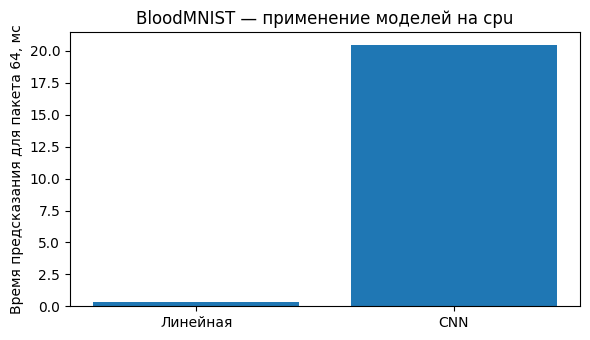

In [58]:
plt.figure(figsize=(6, 3.5))
plt.bar(comparison["Модель"], comparison["Пакет 64, мс"])
plt.ylabel("Время предсказания для пакета 64, мс")
plt.title(f"BloodMNIST — применение моделей на {device}")
plt.tight_layout()
plt.show()

### 6.12. Разберём ошибки CNN

По матрице найдите пару классов с частыми ошибочными переходами.
Название класса можно восстановить по таблице раздела 6.1.
Затем рассмотрим несколько самих изображений.

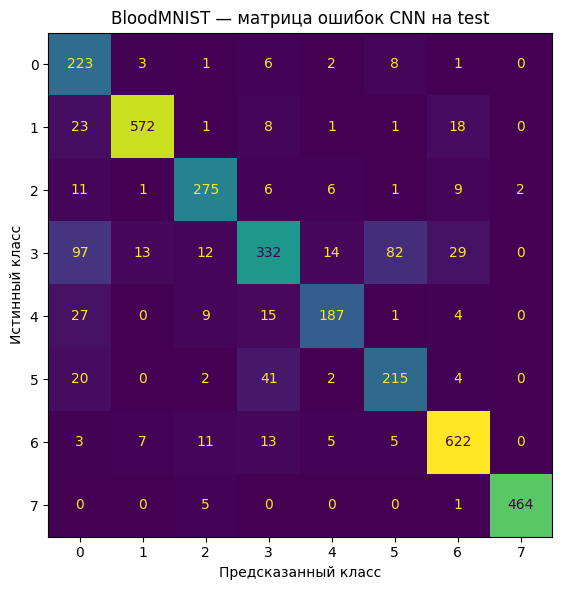

In [59]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    blood_test_labels, blood_predictions["CNN"], labels=range(8),
    ax=ax, colorbar=False
)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title("BloodMNIST — матрица ошибок CNN на test")
plt.tight_layout()
plt.show()

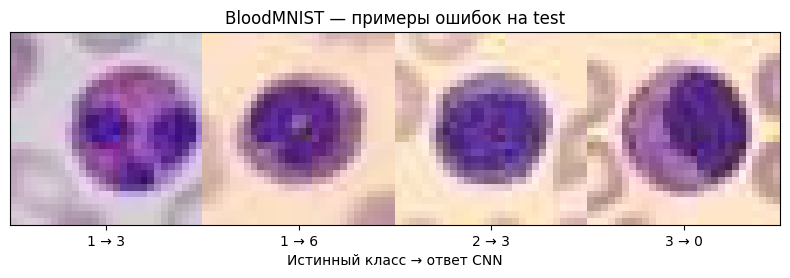

In [60]:
error_indices = np.flatnonzero(blood_predictions["CNN"] != blood_test_labels)[:4]
if len(error_indices) > 0:
    strip = np.concatenate(blood_test_images[error_indices], axis=1)
    captions = [f"{blood_test_labels[i]} → {blood_predictions['CNN'][i]}"
                for i in error_indices]
    plt.figure(figsize=(8, 3))
    plt.imshow(strip)
    plt.xticks(np.arange(len(error_indices)) * 28 + 13.5, captions)
    plt.yticks([])
    plt.xlabel("Истинный класс → ответ CNN")
    plt.title("BloodMNIST — примеры ошибок на test")
    plt.tight_layout()
    plt.show()
else:
    print("На этой тестовой части ошибок нет.")

### 6.13. Сохраним таблицу и сформулируем вывод

Сопоставьте три независимых результата.
Определите, какая модель дала больше верных ответов, какая содержит меньше параметров и какая быстрее обрабатывает пакет.
Объясните наблюдаемое сочетание через работу слоёв, а не через само название модели.

В выводе укажите размер обучающей части, число эпох и устройство.
Добавьте одну наиболее заметную пару перепутанных классов.

Файл `bloodmnist_comparison.csv` содержит фактически измеренные показатели.
Веса CNN сохраняются отдельно.
Для их последующего использования потребуется создать ту же архитектуру и применить то же правило подготовки изображения.

In [61]:
comparison.to_csv("bloodmnist_comparison.csv", index=False)
torch.save(blood_cnn.state_dict(), "bloodmnist_cnn_weights.pt")
print("Сохранены bloodmnist_comparison.csv и bloodmnist_cnn_weights.pt")

Сохранены bloodmnist_comparison.csv и bloodmnist_cnn_weights.pt


## Самостоятельная работа

Откройте `Практика_8_Самостоятельная_CIFAR10.ipynb`.
Он запускается отдельно и не требует объектов из памяти этого блокнота.
В нём нужно обучить одну CNN на трёх классах своего варианта CIFAR-10, уменьшенных до 28 × 28.
Подготовка данных дана, а архитектура и цикл обучения переносятся из раздела 6.
Дополнительный подбор моделей и параметров не требуется.

## Вопросы для проверки понимания

1. Чем различаются `*` и `@`, а `reshape` и `permute`?
2. Почему у `Linear(3, 2)` восемь параметров, независимо от размера пакета?
3. Что отдельно делают `zero_grad()`, `backward()` и `step()`?
4. Что возвращает `Dataset`, а что добавляет `DataLoader`?
5. Почему перед `CrossEntropyLoss` не добавлен `Softmax`?
6. По каким осям вычисляет статистики `BatchNorm2d` и что меняется при `eval()`?
7. Почему небольшая по числу параметров CNN может работать медленнее линейной модели?

## Источники

[1] [Установка PyTorch](https://pytorch.org/get-started/locally/).

[2] [Тензоры и взаимодействие с NumPy](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html).

[3] [nn.Linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html).

[4] [nn.Sequential](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html).

[5] [Автоматическое дифференцирование](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).

[6] [Цикл оптимизации](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

[7] [nn.CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

[8] [Dataset и DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).

[9] [torchvision.datasets.MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).

[10] [ToTensor](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.ToTensor.html).

[11] [MaxPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html).

[12] [AvgPool2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).

[13] [Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).

[14] [BatchNorm2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html).

[15] [Официальные метаданные BloodMNIST, разбиение, классы и контрольная сумма](https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py).

[16] [Синхронизация CUDA](https://docs.pytorch.org/docs/stable/generated/torch.cuda.synchronize.html) и [синхронизация MPS](https://docs.pytorch.org/docs/stable/generated/torch.mps.synchronize.html).